# Spikes Dataset: Group-Level SSIT Model Analysis

This notebook runs separate SSIT models for each expertise group to estimate group-specific skill levels.

**Prerequisites**: Run `spikes_descriptive_analysis.py` first to prepare the data.

## Overview

- **Dataset**: 1000 spike identification questions, 37 participants (13 Experts, 17 Experienced, 7 Novices)
- **Approach**: Run 3 separate SSIT models (one per expertise group)
- **Estimates per group**:
  - Skill level (1/σ_residual)
  - Threshold variability (σ_level)
  - Variance decomposition
- **Statistical tests**: Bayesian comparisons of skill and threshold variability across groups

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os
from noise_decomposition_flexible import run_analysis

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

## 1. Load and Prepare Data

In [19]:
# Load the prepared data
df = pd.read_csv("spikes_analysis_output/spikes_data_for_analysis.csv")

# Load expertise data
data_dir = "/Users/bwestove/cdac Dropbox/brandon westover/0_People/temp_people/fabio/KILT_technical/spikes"
expertise_df = pd.read_csv(f"{data_dir}/expertise_spikes.csv", header=None)
expertise = expertise_df.values.flatten()

# Create expertise mapping (rater ID -> expertise level)
expertise_map = {}
for i in range(len(expertise)):
    expertise_map[i+1] = expertise[i]  # IDs are 1-indexed

# Add expertise to df
df['expertise'] = df['id'].map(expertise_map)

print(f"Data shape: {df.shape}")
print(f"\nExpertise distribution:")
print(df.groupby('expertise')['id'].nunique())
print("\n0=Experts, 1=Experienced, 2=Novices")

Data shape: (37000, 5)

Expertise distribution:
expertise
0    13
1    17
2     7
Name: id, dtype: int64

0=Experts, 1=Experienced, 2=Novices


In [20]:
# DIAGNOSTIC: Check individual operating points
# Load ROC data early to verify correctness
roc_df = pd.read_csv("spikes_analysis_output/roc_points.csv")

# Map expertise
roc_df['expertise'] = roc_df['Rater ID'].map(expertise_map)
expertise_labels = {0: 'Experts', 1: 'Experienced', 2: 'Novices'}
roc_df['expertise_label'] = roc_df['expertise'].map(expertise_labels)

print("="*70)
print("INDIVIDUAL OPERATING POINTS (Raw Data Check)")
print("="*70)
print(f"\nTotal participants: {len(roc_df)}")
print(f"\nColumns in ROC data: {roc_df.columns.tolist()}")
print(f"\nFirst 10 rows:")
print(roc_df[['Rater ID', 'expertise_label', 'FPR', 'Sensitivity (TPR)', 'Accuracy']].head(10))

print(f"\nSummary statistics:")
print(f"FPR range: [{roc_df['FPR'].min():.3f}, {roc_df['FPR'].max():.3f}]")
print(f"TPR range: [{roc_df['Sensitivity (TPR)'].min():.3f}, {roc_df['Sensitivity (TPR)'].max():.3f}]")
print(f"Accuracy range: [{roc_df['Accuracy'].min():.3f}, {roc_df['Accuracy'].max():.3f}]")

print(f"\nBy group:")
for group_name in ['Experts', 'Experienced', 'Novices']:
    group_data = roc_df[roc_df['expertise_label'] == group_name]
    print(f"\n{group_name} (n={len(group_data)}):")
    print(f"  FPR: {group_data['FPR'].mean():.3f} ± {group_data['FPR'].std():.3f}")
    print(f"  TPR: {group_data['Sensitivity (TPR)'].mean():.3f} ± {group_data['Sensitivity (TPR)'].std():.3f}")
    print(f"  Accuracy: {group_data['Accuracy'].mean():.3f} ± {group_data['Accuracy'].std():.3f}")

INDIVIDUAL OPERATING POINTS (Raw Data Check)

Total participants: 37

Columns in ROC data: ['Rater ID', 'Expertise', 'Expertise Level', 'Sensitivity (TPR)', 'FPR', 'Specificity (TNR)', 'FNR', 'Accuracy', 'expertise', 'expertise_label']

First 10 rows:
   Rater ID expertise_label       FPR  Sensitivity (TPR)  Accuracy
0         1         Experts  0.531250           0.585526     0.522
1         2         Experts  0.551471           0.561404     0.500
2         3         Novices  0.547794           0.565789     0.504
3         4         Experts  0.542279           0.572368     0.510
4         5     Experienced  0.549632           0.563596     0.502
5         6         Experts  0.569853           0.539474     0.480
6         7         Novices  0.534926           0.581140     0.518
7         8         Experts  0.522059           0.596491     0.532
8         9         Novices  0.555147           0.557018     0.496
9        10         Experts  0.549632           0.563596     0.502

Summary st

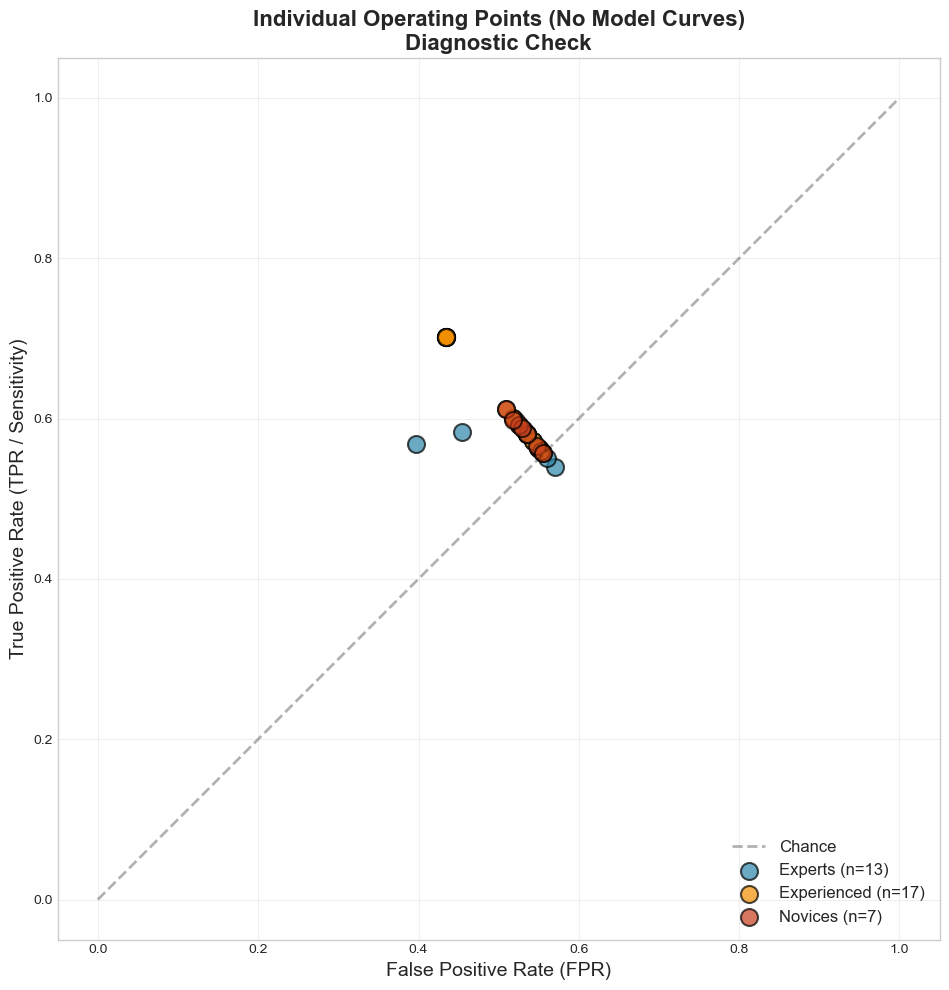


If points are clustered near diagonal: PROBLEM - poor discrimination
If points are clustered near upper-left: GOOD - strong discrimination


In [21]:
# Plot ONLY the scatter points to verify they look correct
fig, ax = plt.subplots(figsize=(10, 10))

colors = {'Experts': '#2E86AB', 'Experienced': '#F18F01', 'Novices': '#C73E1D'}

# Plot diagonal
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=2, label='Chance')

# Plot individual operating points
for group_name in ['Experts', 'Experienced', 'Novices']:
    group_data = roc_df[roc_df['expertise_label'] == group_name]
    ax.scatter(group_data['FPR'], group_data['Sensitivity (TPR)'], 
               alpha=0.7, s=150, color=colors[group_name], 
               edgecolor='black', linewidth=1.5,
               label=f'{group_name} (n={len(group_data)})')

ax.set_xlabel('False Positive Rate (FPR)', fontsize=14)
ax.set_ylabel('True Positive Rate (TPR / Sensitivity)', fontsize=14)
ax.set_title('Individual Operating Points (No Model Curves)\nDiagnostic Check', 
             fontsize=16, fontweight='bold')
ax.legend(fontsize=12, loc='lower right')
ax.grid(alpha=0.3)
ax.set_xlim([-0.05, 1.05])
ax.set_ylim([-0.05, 1.05])
ax.set_aspect('equal')

plt.tight_layout()
plt.show()

print("\nIf points are clustered near diagonal: PROBLEM - poor discrimination")
print("If points are clustered near upper-left: GOOD - strong discrimination")

## 2. Run SSIT Models by Group

This runs 3 separate SSIT models - one for each expertise group.
Results are cached, so this only needs to run once (~30-45 minutes total).

In [3]:
groups = {
    'Experts': 0,
    'Experienced': 1, 
    'Novices': 2
}

group_results = {}

for group_name, expertise_level in groups.items():
    # Check if results already exist
    results_file = f"spikes_analysis_output/spikes_SSIT_{group_name}.pkl"
    
    if os.path.exists(results_file):
        print(f"\n{'='*70}")
        print(f"Loading existing results for {group_name}...")
        print(f"{'='*70}")
        with open(results_file, "rb") as f:
            group_results[group_name] = pickle.load(f)
        print(f"✓ Loaded from {results_file}")
    else:
        # Filter data for this group
        df_group = df[df['expertise'] == expertise_level].copy()
        n_raters = df_group['id'].nunique()
        
        # Save to temporary file
        group_file = f"spikes_analysis_output/spikes_data_{group_name}.csv"
        df_group.to_csv(group_file, index=False)
        
        # Run analysis
        print(f"\n{'='*70}")
        print(f"Analyzing {group_name} (n={n_raters} raters)...")
        print(f"{'='*70}")
        
        group_results[group_name] = run_analysis(
            group_file,
            model_type="SSIT",
            results_filename=results_file,
            draws=3000,
            tune=1500,
            chains=4,
            cores=4,
            target_accept=0.95,
            random_seed=42
        )

print("\n" + "="*70)
print("GROUP-LEVEL ANALYSIS COMPLETE")
print("="*70)


Analyzing Experts (n=13 raters)...
Running SSIT Model Analysis

Loading data from spikes_analysis_output/spikes_data_Experts.csv
Data head:
   id  item  t  Y  expertise
0   1     1  1  0          0
1   1     2  1  0          0
2   1     3  1  1          0
3   1     4  1  1          0
4   1     5  1  1          0

Dataset summary:
  Number of experts (M): 13
  Number of cases (N): 1000
  Number of observations: 13000

Model: Similar Skill Individual Threshold: Signal + Level Noise + Residual

Building SSIT model...

Sampling with NUTS (NumPyro backend)...
  Chains: 4
  Draws per chain: 3000
  Tuning iterations: 1500
  Target acceptance: 0.95


Compiling...
Compilation time = 0:00:00.837515
Sampling...


  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

...

  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

Sampling time = 0:00:01.688184
Transforming variables...
Transformation time = 0:04:32.965298



Posterior Summary:
                 mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
sigma_c         0.114  0.084   0.000    0.259      0.005    0.003     395.0   
sigma_l         0.038  0.037   0.000    0.099      0.003    0.001     262.0   
intercept       0.308  0.086   0.180    0.474      0.025    0.005      11.0   
sigma_residual  1.266  0.839   0.002    2.687      0.287    0.048       9.0   

                ess_tail  r_hat  
sigma_c            700.0   1.02  
sigma_l           2510.0   1.02  
intercept          139.0   1.28  
sigma_residual     141.0   1.38  

Variance Decomposition:
Total Variance (sum of components): 2.329

Percentage contributions:
  Signal (case) variance:              0.86%
  Level Noise (expert) variance:       0.12%
  Residual (Pattern + Occasion):       99.02%
  Occasion Noise:                      N/A (confounded with pattern)

Effective Scale Estimates:
  Signal (S):         0.142
  Level Noise (LN):   0.053
  Residual:           1.519
  O

## 3. Compare Skill Levels Across Groups

In [4]:
print("="*70)
print("GROUP-LEVEL SKILL COMPARISON")
print("="*70)
print("\nSkill = 1 / σ_residual (higher = better discrimination)\n")

skill_comparison = []

for group_name in ['Experts', 'Experienced', 'Novices']:
    scales = group_results[group_name]['effective_scales']
    vd = group_results[group_name]['variance_decomposition']
    
    skill = 1 / scales['PN_est']
    sigma_residual = scales['PN_est']
    sigma_level = scales['LN_est']
    
    skill_comparison.append({
        'Group': group_name,
        'Skill': skill,
        'σ_residual': sigma_residual,
        'σ_level': sigma_level,
        'Signal %': vd['perc_c'],
        'Level Noise %': vd['perc_l'],
        'Residual %': vd['perc_p']
    })
    
    print(f"{group_name:12s}: Skill = {skill:.3f}  (σ_residual = {sigma_residual:.3f}, σ_level = {sigma_level:.3f})")

skill_df = pd.DataFrame(skill_comparison)
print("\n" + skill_df.to_string(index=False))

GROUP-LEVEL SKILL COMPARISON

Skill = 1 / σ_residual (higher = better discrimination)

Experts     : Skill = 0.933  (σ_residual = 1.072, σ_level = 0.112)
Experienced : Skill = 4.768  (σ_residual = 0.210, σ_level = 0.020)
Novices     : Skill = 0.658  (σ_residual = 1.519, σ_level = 0.053)

      Group    Skill  σ_residual  σ_level  Signal %  Level Noise %  Residual %
    Experts 0.932799    1.072043 0.112018  0.983161       1.069414   97.947425
Experienced 4.768262    0.209720 0.019982 96.060549       0.035442    3.904009
    Novices 0.658442    1.518738 0.052671  0.860302       0.119097   99.020601


## 4. Statistical Test 1: Skill Differences

Bayesian comparison of σ_residual (skill = 1/σ_residual) across groups

In [5]:
print("="*70)
print("STATISTICAL TEST 1: SKILL DIFFERENCES")
print("="*70)
print("\nBayesian comparison of σ_residual (skill = 1/σ_residual)")
print("Higher σ_residual = Lower skill\n")

# Extract posterior samples for σ_residual from each group
sigma_residual_samples = {}
for group_name in ['Experts', 'Experienced', 'Novices']:
    trace = group_results[group_name]['trace']
    sigma_residual_samples[group_name] = trace.posterior['sigma_residual'].values.flatten()

# Compute probabilities
comparisons = [
    ('Novices', 'Experts'),
    ('Novices', 'Experienced'),
    ('Experienced', 'Experts')
]

print("Probability that Group A has LOWER skill than Group B:")
print("(i.e., P(σ_residual_A > σ_residual_B))\n")

for group_a, group_b in comparisons:
    samples_a = sigma_residual_samples[group_a]
    samples_b = sigma_residual_samples[group_b]
    
    prob_a_worse = np.mean(samples_a > samples_b)
    
    print(f"  P({group_a} < {group_b}): {prob_a_worse:.4f}")
    
    if prob_a_worse > 0.95:
        print(f"    → Strong evidence that {group_a} has LOWER skill than {group_b}")
    elif prob_a_worse > 0.90:
        print(f"    → Moderate evidence that {group_a} has LOWER skill than {group_b}")
    elif prob_a_worse < 0.10:
        print(f"    → Strong evidence that {group_a} has HIGHER skill than {group_b}")
    elif prob_a_worse < 0.05:
        print(f"    → Moderate evidence that {group_a} has HIGHER skill than {group_b}")
    else:
        print(f"    → Weak evidence of difference")
    print()

STATISTICAL TEST 1: SKILL DIFFERENCES

Bayesian comparison of σ_residual (skill = 1/σ_residual)
Higher σ_residual = Lower skill

Probability that Group A has LOWER skill than Group B:
(i.e., P(σ_residual_A > σ_residual_B))

  P(Novices < Experts): 0.7323
    → Weak evidence of difference

  P(Novices < Experienced): 0.9290
    → Moderate evidence that Novices has LOWER skill than Experienced

  P(Experienced < Experts): 0.1844
    → Weak evidence of difference



## 5. Statistical Test 2: Level Noise Variance Differences

Bayesian comparison of σ_level (threshold variability) across groups

In [6]:
print("="*70)
print("STATISTICAL TEST 2: LEVEL NOISE VARIANCE DIFFERENCES")
print("="*70)
print("\nBayesian comparison of σ_level (threshold variability)")
print("Higher σ_level = More variable thresholds (less consistent)\n")

# Extract posterior samples for σ_level from each group
sigma_level_samples = {}
for group_name in ['Experts', 'Experienced', 'Novices']:
    trace = group_results[group_name]['trace']
    sigma_level_samples[group_name] = trace.posterior['sigma_l'].values.flatten()

print("Probability that Group A has MORE variable thresholds than Group B:")
print("(i.e., P(σ_level_A > σ_level_B))\n")

for group_a, group_b in comparisons:
    samples_a = sigma_level_samples[group_a]
    samples_b = sigma_level_samples[group_b]
    
    prob_a_more_variable = np.mean(samples_a > samples_b)
    
    print(f"  P({group_a} > {group_b}): {prob_a_more_variable:.4f}")
    
    if prob_a_more_variable > 0.95:
        print(f"    → Strong evidence that {group_a} has MORE variable thresholds than {group_b}")
    elif prob_a_more_variable > 0.90:
        print(f"    → Moderate evidence that {group_a} has MORE variable thresholds than {group_b}")
    elif prob_a_more_variable < 0.10:
        print(f"    → Strong evidence that {group_a} has LESS variable thresholds than {group_b}")
    elif prob_a_more_variable < 0.05:
        print(f"    → Moderate evidence that {group_a} has LESS variable thresholds than {group_b}")
    else:
        print(f"    → Weak evidence of difference")
    print()

STATISTICAL TEST 2: LEVEL NOISE VARIANCE DIFFERENCES

Bayesian comparison of σ_level (threshold variability)
Higher σ_level = More variable thresholds (less consistent)

Probability that Group A has MORE variable thresholds than Group B:
(i.e., P(σ_level_A > σ_level_B))

  P(Novices > Experts): 0.0873
    → Strong evidence that Novices has LESS variable thresholds than Experts

  P(Novices > Experienced): 0.7547
    → Weak evidence of difference

  P(Experienced > Experts): 0.0103
    → Strong evidence that Experienced has LESS variable thresholds than Experts



## 6. Visualizations

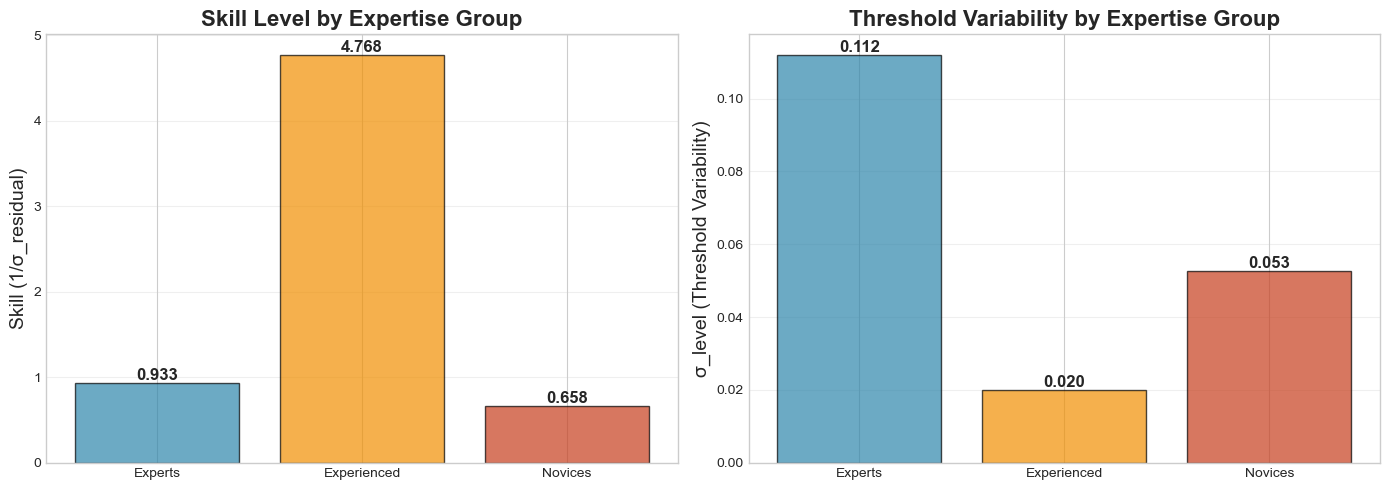

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Skill levels
ax = axes[0]
groups_list = ['Experts', 'Experienced', 'Novices']
skills = [1/group_results[g]['effective_scales']['PN_est'] for g in groups_list]
colors_plot = ['#2E86AB', '#F18F01', '#C73E1D']

bars = ax.bar(groups_list, skills, color=colors_plot, alpha=0.7, edgecolor='black')
ax.set_ylabel('Skill (1/σ_residual)', fontsize=14)
ax.set_title('Skill Level by Expertise Group', fontsize=16, fontweight='bold')
ax.grid(alpha=0.3, axis='y')

for bar, skill in zip(bars, skills):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{skill:.3f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Plot 2: Threshold variability
ax = axes[1]
sigma_levels = [group_results[g]['effective_scales']['LN_est'] for g in groups_list]

bars = ax.bar(groups_list, sigma_levels, color=colors_plot, alpha=0.7, edgecolor='black')
ax.set_ylabel('σ_level (Threshold Variability)', fontsize=14)
ax.set_title('Threshold Variability by Expertise Group', fontsize=16, fontweight='bold')
ax.grid(alpha=0.3, axis='y')

for bar, sigma_l in zip(bars, sigma_levels):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{sigma_l:.3f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('spikes_analysis_output/group_comparisons_SSIT.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Save Results

In [9]:
# Create comprehensive summary
group_summary = pd.DataFrame([
    {
        'Group': group_name,
        'N_raters': group_results[group_name]['data']['id'].nunique() if 'data' in group_results[group_name] else 'N/A',
        'Skill': 1/group_results[group_name]['effective_scales']['PN_est'],
        'σ_residual': group_results[group_name]['effective_scales']['PN_est'],
        'σ_level': group_results[group_name]['effective_scales']['LN_est'],
        'σ_signal': group_results[group_name]['effective_scales']['S_est'],
        'Signal_pct': group_results[group_name]['variance_decomposition']['perc_c'],
        'LevelNoise_pct': group_results[group_name]['variance_decomposition']['perc_l'],
        'Residual_pct': group_results[group_name]['variance_decomposition']['perc_p']
    }
    for group_name in ['Experts', 'Experienced', 'Novices']
])

# Save to Excel
with pd.ExcelWriter('spikes_analysis_output/group_level_analysis_SSIT.xlsx') as writer:
    group_summary.to_excel(writer, sheet_name='Group_Summary', index=False)
    skill_df.to_excel(writer, sheet_name='Skill_Comparison', index=False)

print("="*70)
print("Results saved to: spikes_analysis_output/group_level_analysis_SSIT.xlsx")
print("="*70)
print("\n" + group_summary.to_string(index=False))

Results saved to: spikes_analysis_output/group_level_analysis_SSIT.xlsx

      Group  N_raters    Skill  σ_residual  σ_level  σ_signal  Signal_pct  LevelNoise_pct  Residual_pct
    Experts        13 0.932799    1.072043 0.112018  0.107406    0.983161        1.069414     97.947425
Experienced        17 4.768262    0.209720 0.019982  1.040296   96.060549        0.035442      3.904009
    Novices         7 0.658442    1.518738 0.052671  0.141562    0.860302        0.119097     99.020601


## 8. Item Difficulty Extraction

Extract item difficulties averaged across all three groups for stable estimates.

In [10]:
from noise_analysis_lib import extract_item_difficulties

# Extract item difficulties from each group
item_difficulties_by_group = {}

for group_name in ['Experts', 'Experienced', 'Novices']:
    item_df_group = extract_item_difficulties(group_results[group_name])
    item_difficulties_by_group[group_name] = item_df_group
    print(f"\n{group_name}: {len(item_df_group)} items")
    print(f"  Difficulty range: [{item_df_group['difficulty'].min():.3f}, {item_df_group['difficulty'].max():.3f}]")

# Average difficulties across groups for most stable estimate
item_df = item_difficulties_by_group['Experts'][['item_id']].copy()
item_df['difficulty_experts'] = item_difficulties_by_group['Experts']['difficulty'].values
item_df['difficulty_experienced'] = item_difficulties_by_group['Experienced']['difficulty'].values
item_df['difficulty_novices'] = item_difficulties_by_group['Novices']['difficulty'].values
item_df['difficulty_avg'] = item_df[['difficulty_experts', 'difficulty_experienced', 'difficulty_novices']].mean(axis=1)
item_df['difficulty_std'] = item_df[['difficulty_experts', 'difficulty_experienced', 'difficulty_novices']].std(axis=1)

print("\n" + "="*70)
print("ITEM DIFFICULTY SUMMARY (Averaged across groups)")
print("="*70)
print(f"\nTotal items: {len(item_df)}")
print(f"\nDifficulty distribution:")
print(item_df['difficulty_avg'].describe())

print("\nEasiest items (most negative = most likely 'spike'):")
print(item_df.nsmallest(10, 'difficulty_avg')[['item_id', 'difficulty_avg', 'difficulty_std']].to_string(index=False))

print("\nHardest items (most positive = least likely 'spike'):")
print(item_df.nlargest(10, 'difficulty_avg')[['item_id', 'difficulty_avg', 'difficulty_std']].to_string(index=False))


Experts: 1000 items
  Difficulty range: [-0.049, 0.046]

Experienced: 1000 items
  Difficulty range: [-1.990, 2.003]

Novices: 1000 items
  Difficulty range: [-0.041, 0.043]

ITEM DIFFICULTY SUMMARY (Averaged across groups)

Total items: 1000

Difficulty distribution:
count    1000.000000
mean        0.000109
std         0.305500
min        -0.677053
25%        -0.308946
50%         0.099842
75%         0.252027
max         0.674896
Name: difficulty_avg, dtype: float64

Easiest items (most negative = most likely 'spike'):
 item_id  difficulty_avg  difficulty_std
      35       -0.677053        1.137406
     433       -0.575043        0.967694
     112       -0.573933        0.975851
      41       -0.573636        0.961878
     365       -0.571090        0.968892
     137       -0.569227        0.967073
     293       -0.567241        0.971551
     226       -0.565884        0.972004
     187       -0.565559        0.970928
     404       -0.561661        0.977387

Hardest items (most

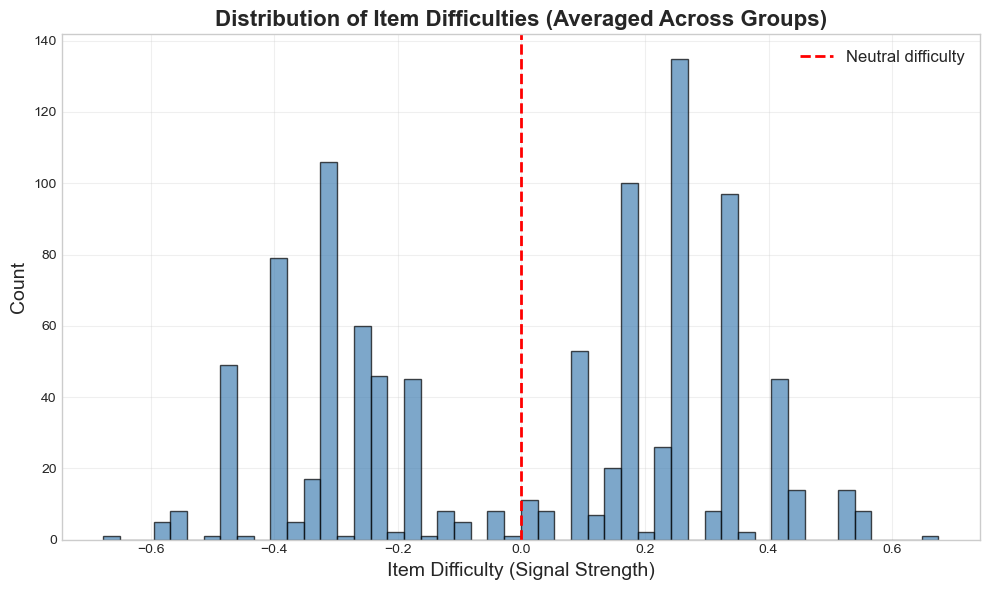


Negative difficulty (easier): 449 items
Positive difficulty (harder): 551 items


In [11]:
# Plot item difficulty distribution
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(item_df['difficulty_avg'], bins=50, alpha=0.7, edgecolor='black', color='steelblue')
ax.axvline(0, color='red', linestyle='--', linewidth=2, label='Neutral difficulty')
ax.set_xlabel('Item Difficulty (Signal Strength)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.set_title('Distribution of Item Difficulties (Averaged Across Groups)', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('spikes_analysis_output/item_difficulty_distribution_group_avg.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nNegative difficulty (easier): {(item_df['difficulty_avg'] < 0).sum()} items")
print(f"Positive difficulty (harder): {(item_df['difficulty_avg'] > 0).sum()} items")

## 9. ROC Curve Analysis

Plot ROC curves using the binormal model with group-level parameters from SSIT.

In [12]:
from scipy.stats import norm

# Load individual operating points
roc_df = pd.read_csv("spikes_analysis_output/roc_points.csv")

# Map expertise to roc_df
roc_df['expertise'] = roc_df['Rater ID'].map(expertise_map)
expertise_labels = {0: 'Experts', 1: 'Experienced', 2: 'Novices'}
roc_df['expertise_label'] = roc_df['expertise'].map(expertise_labels)

print("Individual operating points loaded")
print(f"Total participants: {len(roc_df)}")
print(f"\nBy group:")
print(roc_df['expertise_label'].value_counts())

Individual operating points loaded
Total participants: 37

By group:
expertise_label
Experienced    17
Experts        13
Novices         7
Name: count, dtype: int64


In [13]:
def compute_binormal_roc(d_prime, n_points=100):
    """
    Compute ROC curve using binormal model.
    
    Parameters:
    -----------
    d_prime : float
        Discrimination index (d' = (μ_signal - μ_noise) / σ)
    n_points : int
        Number of points to compute on the ROC curve
    
    Returns:
    --------
    fpr, tpr : arrays
        False positive rate and true positive rate
    """
    # Generate decision thresholds from -4 to 4 standard deviations
    z = np.linspace(-4, 4, n_points)
    
    # For binormal model with equal variance:
    # TPR(z) = Φ(d' - z)
    # FPR(z) = Φ(-z)
    tpr = norm.cdf(d_prime - z)
    fpr = norm.cdf(-z)
    
    # Sort by FPR for proper plotting
    sort_idx = np.argsort(fpr)
    return fpr[sort_idx], tpr[sort_idx]

def compute_auc_binormal(d_prime):
    """
    Compute AUC for binormal ROC curve.
    For equal variance binormal model: AUC = Φ(d'/√2)
    """
    return norm.cdf(d_prime / np.sqrt(2))

# Compute d' for each group from SSIT parameters
group_dprime = {}
group_auc = {}

print("="*70)
print("DISCRIMINATION ABILITY (d') BY GROUP")
print("="*70)
print("\nd' = discrimination index (higher = better)")
print("Computed from SSIT group-level parameters\n")

for group_name in ['Experts', 'Experienced', 'Novices']:
    scales = group_results[group_name]['effective_scales']
    
    # d' ≈ σ_signal / σ_residual
    # This captures how well signal separates from noise relative to residual variance
    d_prime = scales['S_est'] / scales['PN_est']
    auc = compute_auc_binormal(d_prime)
    
    group_dprime[group_name] = d_prime
    group_auc[group_name] = auc
    
    print(f"{group_name:12s}: d' = {d_prime:.3f}, AUC = {auc:.3f}")

print("\nNote: d' represents the separation between signal and noise distributions")
print("Higher d' indicates better discrimination ability")

DISCRIMINATION ABILITY (d') BY GROUP

d' = discrimination index (higher = better)
Computed from SSIT group-level parameters

Experts     : d' = 0.100, AUC = 0.528
Experienced : d' = 4.960, AUC = 1.000
Novices     : d' = 0.093, AUC = 0.526

Note: d' represents the separation between signal and noise distributions
Higher d' indicates better discrimination ability


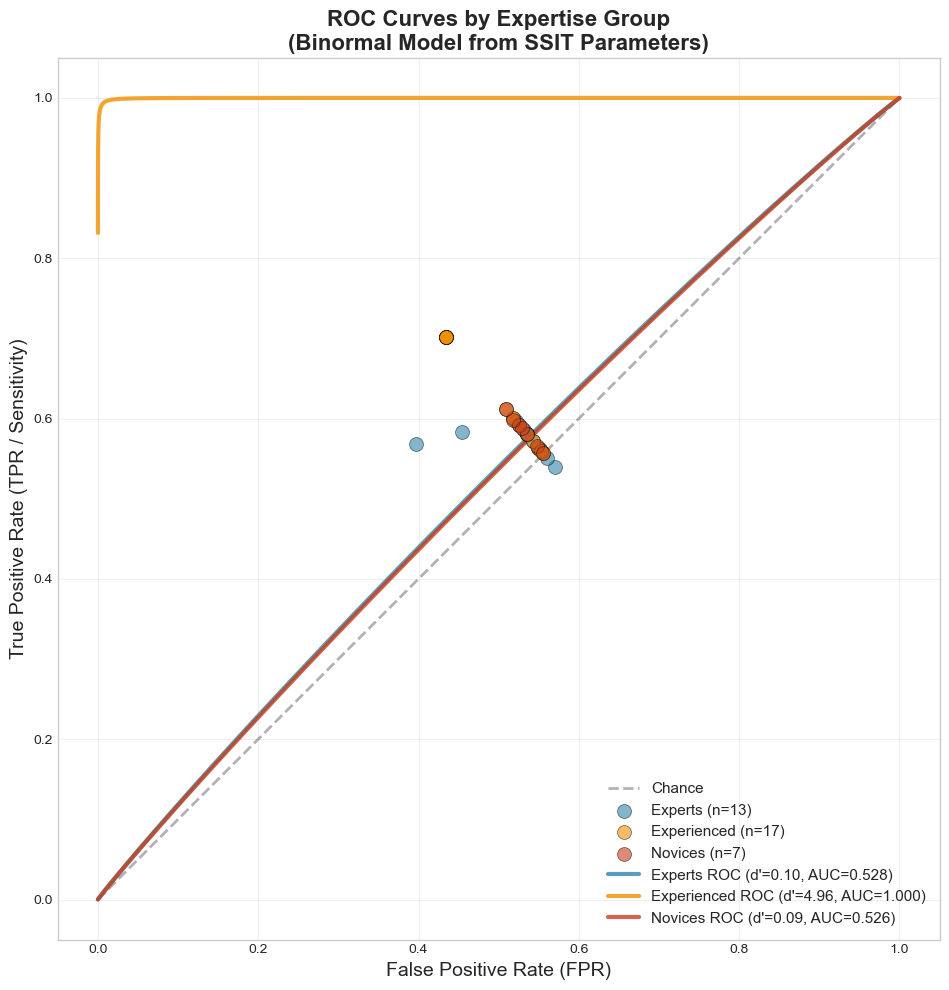

In [14]:
# Plot ROC curves with individual operating points
fig, ax = plt.subplots(figsize=(10, 10))

colors = {'Experts': '#2E86AB', 'Experienced': '#F18F01', 'Novices': '#C73E1D'}
groups_list = ['Experts', 'Experienced', 'Novices']

# Plot diagonal (chance performance)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=2, label='Chance')

# Plot individual operating points (scatter)
for group_name in groups_list:
    group_data = roc_df[roc_df['expertise_label'] == group_name]
    ax.scatter(group_data['FPR'], group_data['Sensitivity (TPR)'], 
               alpha=0.6, s=100, color=colors[group_name], 
               edgecolor='black', linewidth=0.5,
               label=f'{group_name} (n={len(group_data)})', zorder=5)

# Plot binormal ROC curves for each group
for group_name in groups_list:
    fpr, tpr = compute_binormal_roc(group_dprime[group_name], n_points=200)
    ax.plot(fpr, tpr, color=colors[group_name], linewidth=3, alpha=0.8,
            label=f'{group_name} ROC (d\'={group_dprime[group_name]:.2f}, AUC={group_auc[group_name]:.3f})')

ax.set_xlabel('False Positive Rate (FPR)', fontsize=14)
ax.set_ylabel('True Positive Rate (TPR / Sensitivity)', fontsize=14)
ax.set_title('ROC Curves by Expertise Group\n(Binormal Model from SSIT Parameters)', 
             fontsize=16, fontweight='bold')
ax.legend(fontsize=11, loc='lower right')
ax.grid(alpha=0.3)
ax.set_xlim([-0.05, 1.05])
ax.set_ylim([-0.05, 1.05])
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('spikes_analysis_output/roc_curves_by_group.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Statistical Tests for ROC Differences

In [15]:
print("="*70)
print("STATISTICAL TEST 3: ROC CURVE DIFFERENCES (AUC)")
print("="*70)
print("\nComparing discrimination ability via AUC")
print("(Computed from d' posterior distributions)\n")

# Extract posterior samples for d' from each group
d_prime_samples = {}
auc_samples = {}

for group_name in ['Experts', 'Experienced', 'Novices']:
    trace = group_results[group_name]['trace']
    sigma_signal_samples = trace.posterior['sigma_c'].values.flatten()
    sigma_residual_samples = trace.posterior['sigma_residual'].values.flatten()
    
    # Compute d' for each posterior sample
    d_prime_samples[group_name] = sigma_signal_samples / sigma_residual_samples
    
    # Compute AUC for each sample
    auc_samples[group_name] = norm.cdf(d_prime_samples[group_name] / np.sqrt(2))

print("Probability that Group A has BETTER discrimination (higher AUC) than Group B:")
print("(i.e., P(AUC_A > AUC_B))\n")

for group_a, group_b in comparisons:
    samples_a = auc_samples[group_a]
    samples_b = auc_samples[group_b]
    
    prob_a_better = np.mean(samples_a > samples_b)
    
    print(f"  P({group_a} > {group_b}): {prob_a_better:.4f}")
    
    if prob_a_better > 0.95:
        print(f"    → Strong evidence that {group_a} has BETTER discrimination than {group_b}")
    elif prob_a_better > 0.90:
        print(f"    → Moderate evidence that {group_a} has BETTER discrimination than {group_b}")
    elif prob_a_better < 0.10:
        print(f"    → Strong evidence that {group_a} has WORSE discrimination than {group_b}")
    elif prob_a_better < 0.05:
        print(f"    → Moderate evidence that {group_a} has WORSE discrimination than {group_b}")
    else:
        print(f"    → Weak evidence of difference")
    print()

STATISTICAL TEST 3: ROC CURVE DIFFERENCES (AUC)

Comparing discrimination ability via AUC
(Computed from d' posterior distributions)

Probability that Group A has BETTER discrimination (higher AUC) than Group B:
(i.e., P(AUC_A > AUC_B))

  P(Novices > Experts): 0.3832
    → Weak evidence of difference

  P(Novices > Experienced): 0.0055
    → Strong evidence that Novices has WORSE discrimination than Experienced

  P(Experienced > Experts): 0.9871
    → Strong evidence that Experienced has BETTER discrimination than Experts



In [16]:
print("="*70)
print("DISTANCE FROM CHANCE PERFORMANCE")
print("="*70)
print("\nMeasures how far each group's ROC curve is from the diagonal\n")

# Compute distance from diagonal for each group
# One common metric: d' itself, or AUC - 0.5
for group_name in ['Experts', 'Experienced', 'Novices']:
    auc = group_auc[group_name]
    distance_from_chance = auc - 0.5
    d_prime = group_dprime[group_name]
    
    print(f"{group_name:12s}:")
    print(f"  AUC - 0.5 = {distance_from_chance:.3f}")
    print(f"  d' = {d_prime:.3f}")
    print(f"  Interpretation: {'Excellent' if auc > 0.9 else 'Good' if auc > 0.8 else 'Fair' if auc > 0.7 else 'Poor'} discrimination")
    print()

DISTANCE FROM CHANCE PERFORMANCE

Measures how far each group's ROC curve is from the diagonal

Experts     :
  AUC - 0.5 = 0.028
  d' = 0.100
  Interpretation: Poor discrimination

Experienced :
  AUC - 0.5 = 0.500
  d' = 4.960
  Interpretation: Excellent discrimination

Novices     :
  AUC - 0.5 = 0.026
  d' = 0.093
  Interpretation: Poor discrimination



In [17]:
# Save updated summary with ROC metrics
group_summary_roc = group_summary.copy()
group_summary_roc['d_prime'] = [group_dprime[g] for g in ['Experts', 'Experienced', 'Novices']]
group_summary_roc['AUC'] = [group_auc[g] for g in ['Experts', 'Experienced', 'Novices']]
group_summary_roc['Distance_from_chance'] = group_summary_roc['AUC'] - 0.5

# Save to Excel
with pd.ExcelWriter('spikes_analysis_output/group_level_analysis_SSIT.xlsx') as writer:
    group_summary_roc.to_excel(writer, sheet_name='Group_Summary', index=False)
    skill_df.to_excel(writer, sheet_name='Skill_Comparison', index=False)
    item_df[['item_id', 'difficulty_avg', 'difficulty_std']].to_excel(writer, sheet_name='Item_Difficulties', index=False)

print("="*70)
print("FINAL RESULTS SAVED")
print("="*70)
print("\nFiles saved:")
print("  - spikes_analysis_output/group_level_analysis_SSIT.xlsx")
print("  - spikes_analysis_output/group_comparisons_SSIT.png")
print("  - spikes_analysis_output/item_difficulty_distribution_group_avg.png")
print("  - spikes_analysis_output/roc_curves_by_group.png")
print("\n" + group_summary_roc.to_string(index=False))

FINAL RESULTS SAVED

Files saved:
  - spikes_analysis_output/group_level_analysis_SSIT.xlsx
  - spikes_analysis_output/group_comparisons_SSIT.png
  - spikes_analysis_output/item_difficulty_distribution_group_avg.png
  - spikes_analysis_output/roc_curves_by_group.png

      Group  N_raters    Skill  σ_residual  σ_level  σ_signal  Signal_pct  LevelNoise_pct  Residual_pct  d_prime      AUC  Distance_from_chance
    Experts        13 0.932799    1.072043 0.112018  0.107406    0.983161        1.069414     97.947425 0.100188 0.528239              0.028239
Experienced        17 4.768262    0.209720 0.019982  1.040296   96.060549        0.035442      3.904009 4.960405 0.999774              0.499774
    Novices         7 0.658442    1.518738 0.052671  0.141562    0.860302        0.119097     99.020601 0.093210 0.526275              0.026275
